In [29]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [9]:
df = pd.read_csv('../../course_assignments/homework8/state_data.csv')

print(f"Shape of data: {df.shape}")
print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")

print(df.head()) #Displays first 5 rows
print(df.tail()) #Displays last 5 rows

# What do different columns represent?
#state: Name/abbreviation of the state or region.
#latitude: The geographical latitude coordinate of the location.
#longitutde: The geographical longitute coordinate of the location

# What is the first state?
print(df.head(1)) # Alaska

# What is the last state?
print(df.tail(1)) # Wyoming

#Total entries?
print(len(df)) #52

# Why are there more than 50 states listed?
#The dataset includes US territories, districts and other outlying islands in addition to the official 50 states.

Shape of data: (52, 4)
Number of rows: 52
Number of columns: 4
  state   latitude   longitude        name
0    AK  63.588753 -154.493062      Alaska
1    AL  32.318231  -86.902298     Alabama
2    AR  35.201050  -91.831833    Arkansas
3    AZ  34.048928 -111.093731     Arizona
4    CA  36.778261 -119.417932  California
   state   latitude   longitude           name
47    VT  44.558803  -72.577841        Vermont
48    WA  47.751074 -120.740139     Washington
49    WI  43.784440  -88.787868      Wisconsin
50    WV  38.597626  -80.454903  West Virginia
51    WY  43.075968 -107.290284        Wyoming
  state   latitude   longitude    name
0    AK  63.588753 -154.493062  Alaska
   state   latitude   longitude     name
51    WY  43.075968 -107.290284  Wyoming
52


In [10]:
median_lat = df["latitude"].median()
median_long = df["longitude"].median()

print(f"Median Latitude: {median_lat}")
print(f"Median Longitude: {median_long}")

Median Latitude: 39.4355155
Median Longitude: -89.093198


In [11]:
df["lat_dist"] = (df["latitude"] - median_lat).abs() #Absolute distance to median latitude

df["long_dist"] = (df["longitude"] - median_long).abs() #Absolute distance to median longitude

In [13]:
print(f"New DataFrame shape: {df.shape}")
print(f"Columns now: {df.shape[1]} (added lat_dist and long_dist)")
print(f"Rows now: {df.shape[0]}")

New DataFrame shape: (52, 6)
Columns now: 6 (added lat_dist and long_dist)
Rows now: 52


In [15]:
# Latitude closest & farthest
idx_min_lat = df["lat_dist"].idxmin()
idx_max_lat = df["lat_dist"].idxmax()

state_min_lat = df.loc[idx_min_lat, "state"]
dist_min_lat = df.loc[idx_min_lat, "lat_dist"]

state_max_lat = df.loc[idx_max_lat, "state"]
dist_max_lat = df.loc[idx_max_lat, "lat_dist"]

# Longitude closest & farthest
idx_min_long = df["long_dist"].idxmin()
idx_max_long = df["long_dist"].idxmax()

state_min_long = df.loc[idx_min_long, "state"]
dist_min_long = df.loc[idx_min_long, "long_dist"]

state_max_long = df.loc[idx_max_long, "state"]
dist_max_long = df.loc[idx_max_long, "long_dist"]

# Print statements formatted to two decimal places
print(f"State closest to median latitude: {state_min_lat} by {dist_min_lat:.2f} degrees")
print(f"State farthest from median latitude: {state_max_lat} by {dist_max_lat:.2f} degrees")
print(f"State closest to median longitude: {state_min_long} by {dist_min_long:.2f} degrees")
print(f"State farthest from median longitude: {state_max_long} by {dist_max_long:.2f} degrees")

State closest to median latitude: CO by 0.11 degrees
State farthest from median latitude: AK by 24.15 degrees
State closest to median longitude: IL by 0.31 degrees
State farthest from median longitude: HI by 66.57 degrees


In [17]:
top_latitudes = df.nlargest(5, "latitude")
print(top_latitudes)

#Where found: Pandas Documentation - DataFrame Reference under Reordering / sorting / rearranging.
#Function & Purpose: .nlargest(n, columns) returns the top n rows ordered by specified column values in descending order.
#Why useful: It quickly filters out top extreme values (like the 5 northernmost states) without having to manually sort the entire DataFrame using .sort_values().

   state   latitude   longitude          name   lat_dist  long_dist
0     AK  63.588753 -154.493062        Alaska  24.153237  65.399864
48    WA  47.751074 -120.740139    Washington   8.315559  31.646941
28    ND  47.551493 -101.002012  North Dakota   8.115977  11.908814
26    MT  46.879682 -110.362566       Montana   7.444167  21.269368
23    MN  46.729553  -94.685900     Minnesota   7.294038   5.592702


In [18]:
import seaborn as sns

In [19]:
seaborn_df = sns.load_dataset("planets")

In [21]:
planets_clean = seaborn_df.dropna(axis=1)

In [23]:
print(f"Dataset shape: {planets_clean.shape}")
print(f"Number of rows: {planets_clean.shape[0]}")
print(f"Number of columns: {planets_clean.shape[1]}")

print("\n--- First 5 Rows ---")
print(planets_clean.head())

print("\n--- Last 5 Rows ---")
print(planets_clean.tail())

print("\n--- Remaining Columns ---")
print(planets_clean.columns.tolist())

#Shape: (1035, 3) — 1,035 rows and 3 columns (after dropping columns with NaN values).

# Column Descriptions:
#method: The observational method used to discover the exoplanet (e.g., Radial Velocity, Transit, Imaging).
#number: The number of confirmed planets in that star system.
#year: The year the exoplanet was discovered.

Dataset shape: (1035, 3)
Number of rows: 1035
Number of columns: 3

--- First 5 Rows ---
            method  number  year
0  Radial Velocity       1  2006
1  Radial Velocity       1  2008
2  Radial Velocity       1  2011
3  Radial Velocity       1  2007
4  Radial Velocity       1  2009

--- Last 5 Rows ---
       method  number  year
1030  Transit       1  2006
1031  Transit       1  2007
1032  Transit       1  2007
1033  Transit       1  2008
1034  Transit       1  2008

--- Remaining Columns ---
['method', 'number', 'year']


/var/folders/t7/k3ng5zfj6jb938s2vfs9yn5r0000gn/T/ipykernel_2413/2769629177.py:46: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


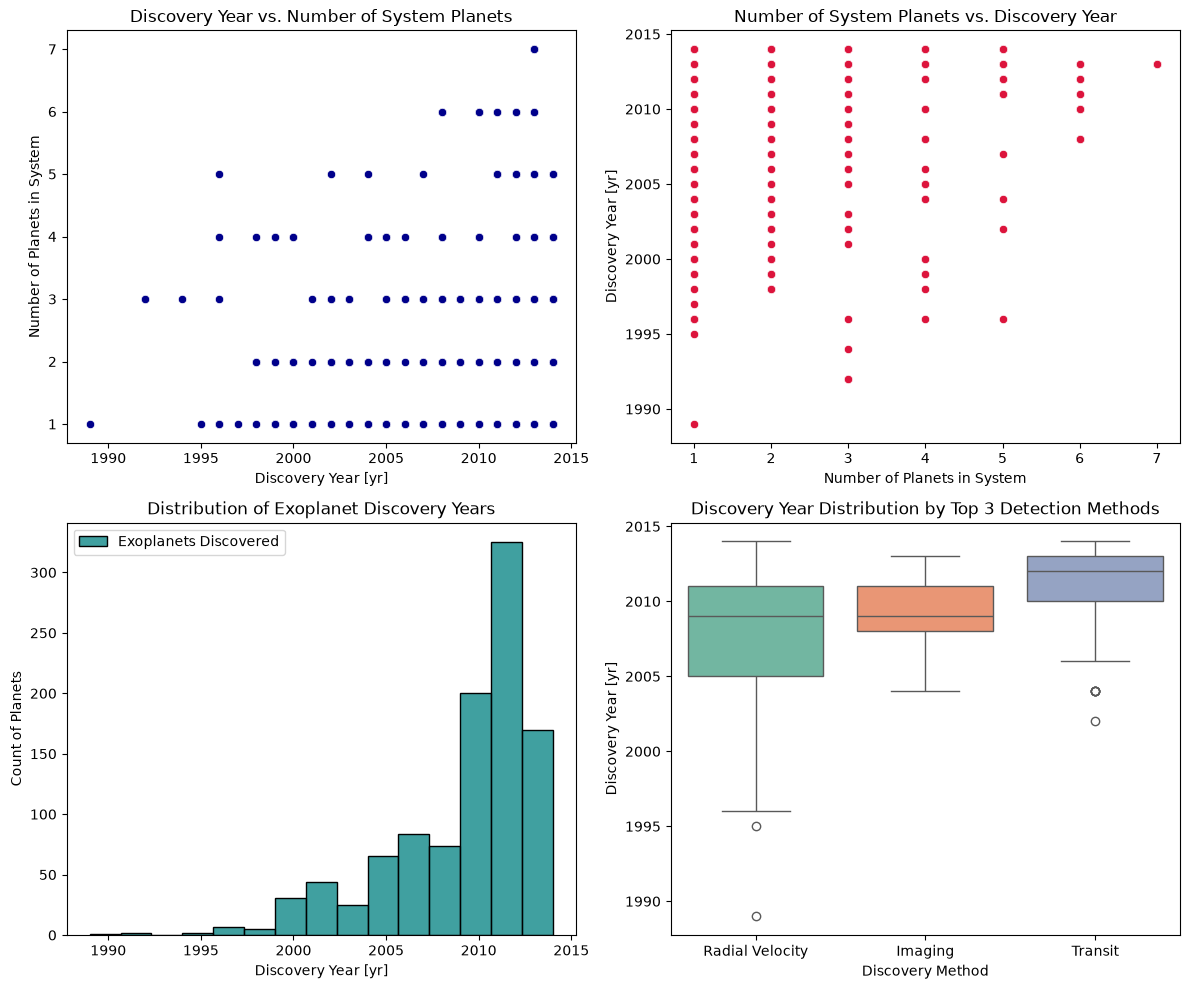

In [27]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

# Subplot 1 (Top-Left): Scatter plot (Year vs. Number of Planets)
sns.scatterplot(
    data=planets_clean, 
    x="year", 
    y="number", 
    color="darkblue", 
    ax=axes[0, 0]
)
axes[0, 0].set_title("Discovery Year vs. Number of System Planets")
axes[0, 0].set_xlabel("Discovery Year [yr]")
axes[0, 0].set_ylabel("Number of Planets in System")

# Subplot 2 (Top-Right): Scatter plot (Swapped axes to meet requirement)
sns.scatterplot(
    data=planets_clean, 
    x="number", 
    y="year", 
    color="crimson", 
    ax=axes[0, 1]
)
axes[0, 1].set_title("Number of System Planets vs. Discovery Year")
axes[0, 1].set_xlabel("Number of Planets in System")
axes[0, 1].set_ylabel("Discovery Year [yr]")

# Subplot 3 (Bottom-Left): Histogram of Discovery Years
sns.histplot(
    data=planets_clean, 
    x="year", 
    bins=15, 
    color="teal", 
    label="Exoplanets Discovered", 
    ax=axes[1, 0]
)
axes[1, 0].set_title("Distribution of Exoplanet Discovery Years")
axes[1, 0].set_xlabel("Discovery Year [yr]")
axes[1, 0].set_ylabel("Count of Planets")
axes[1, 0].legend()

# Subplot 4 (Bottom-Right): Categorical Boxplot (Discovery Year by Method)
# Filtering to top 3 methods so plot categories remain legible
top_methods = planets_clean["method"].value_counts().nlargest(3).index
df_top = planets_clean[planets_clean["method"].isin(top_methods)]

sns.boxplot(
    data=df_top, 
    x="method", 
    y="year", 
    palette="Set2", 
    ax=axes[1, 1]
)
axes[1, 1].set_title("Discovery Year Distribution by Top 3 Detection Methods")
axes[1, 1].set_xlabel("Discovery Method")
axes[1, 1].set_ylabel("Discovery Year [yr]")

plt.tight_layout()
plt.show()

In [28]:
# Explanations

#Top-Left Subplot (Scatter Plot: Year vs. Number): Shows when multi-planet systems were detected relative to single-planet systems over time.
#Top-Right Subplot (Scatter Plot: Number vs. Year): Reverses the axes to inspect system size groupings across years.
#Bottom-Left Subplot (Histogram: Discovery Year): Displays the growth in exoplanet detections per year.
#Bottom-Right Subplot (Boxplot: Method vs. Year): Compares the timeline profile of the top three discovery methods (Radial Velocity, Transit, Imaging).

# Learnings:
#Exoplanet discoveries surged significantly around 2009–2014, corresponding with space mission operational phases like NASA's Kepler Space Telescope.
#Radial Velocity was the primary detection method in earlier years, whereas the Transit method dominates in recent years.

In [33]:
df = pd.read_csv("exoplanet_data.csv", comment="#")

print("Shape of dataset:", df.shape)
print(f"Number of rows: {df.shape[0]}, Number of columns: {df.shape[1]}")

print("All Column Titles:")
print(df.columns.tolist())

# 5 column titles:
#1. pl_orbper - Planet Orbital Period
#2. pl_orbeccen - Planet Eccentricity
#3. st_teff - Stellar Effective Temperature
#4. st_rad - Stellar Radius
#5. sy_dist - System Distance

Shape of dataset: (599, 92)
Number of rows: 599, Number of columns: 92
All Column Titles:
['pl_name', 'hostname', 'default_flag', 'sy_snum', 'sy_pnum', 'discoverymethod', 'disc_year', 'disc_facility', 'soltype', 'pl_controv_flag', 'pl_refname', 'pl_orbper', 'pl_orbpererr1', 'pl_orbpererr2', 'pl_orbperlim', 'pl_orbsmax', 'pl_orbsmaxerr1', 'pl_orbsmaxerr2', 'pl_orbsmaxlim', 'pl_rade', 'pl_radeerr1', 'pl_radeerr2', 'pl_radelim', 'pl_radj', 'pl_radjerr1', 'pl_radjerr2', 'pl_radjlim', 'pl_bmasse', 'pl_bmasseerr1', 'pl_bmasseerr2', 'pl_bmasselim', 'pl_bmassj', 'pl_bmassjerr1', 'pl_bmassjerr2', 'pl_bmassjlim', 'pl_bmassprov', 'pl_orbeccen', 'pl_orbeccenerr1', 'pl_orbeccenerr2', 'pl_orbeccenlim', 'pl_insol', 'pl_insolerr1', 'pl_insolerr2', 'pl_insollim', 'pl_eqt', 'pl_eqterr1', 'pl_eqterr2', 'pl_eqtlim', 'ttv_flag', 'st_refname', 'st_spectype', 'st_teff', 'st_tefferr1', 'st_tefferr2', 'st_tefflim', 'st_rad', 'st_raderr1', 'st_raderr2', 'st_radlim', 'st_mass', 'st_masserr1', 'st_masserr2', 'st_

In [34]:
# Database Column Names corresponding to Table Labels:
# Planet Name: pl_name
# Host Name: hostname
# Discovery Method: discoverymethod
# Spectral Type: st_spectype
# Equilibrium Temperature [K]: pl_eqt
# Planet Mass or Mass*sin(i) [Jupiter Mass]: pl_bmassj

cols = [
    'pl_name',          # Planet Name: Name of the exoplanet
    'hostname',         # Host Name: Name of the host star
    'discoverymethod',  # Discovery Method: Method used to discover the planet
    'st_spectype',      # Spectral Type: Spectral classification of the host star
    'pl_eqt',           # Equilibrium Temperature [K]: Planet's estimated temperature in Kelvin
    'pl_bmassj'         # Planet Mass [Jupiter Mass]: Mass of the planet relative to Jupiter
]

df_reduced = df[cols].copy() #smaller data frame

df_filtered = df_reduced.dropna().reset_index(drop=True)

print("Shape of filtered dataset:", df_filtered.shape)
print(f"Number of rows: {df_filtered.shape[0]}, Number of columns: {df_filtered.shape[1]}")

print("\nFirst 5 rows:")
print(df_filtered.head())

print("\nLast 5 rows:")
print(df_filtered.tail())

print("\nFiltered Column Titles:")
print(df_filtered.columns.tolist())

Shape of filtered dataset: (77, 6)
Number of rows: 77, Number of columns: 6

First 5 rows:
    pl_name hostname  discoverymethod st_spectype  pl_eqt  pl_bmassj
0  DMPP-1 b   DMPP-1  Radial Velocity        F8 V   877.0   0.076362
1  DMPP-1 c   DMPP-1  Radial Velocity        F8 V  1239.0   0.030205
2  DMPP-1 d   DMPP-1  Radial Velocity        F8 V  1632.0   0.010540
3  DMPP-1 e   DMPP-1  Radial Velocity        F8 V  1314.0   0.012994
4  DMPP-2 b   DMPP-2  Radial Velocity        F5 V  1000.0   0.437000

Last 5 rows:
        pl_name   hostname  discoverymethod st_spectype  pl_eqt  pl_bmassj
72   WASP-185 b   WASP-185          Transit        G0 V  1160.0      0.980
73   WASP-190 b   WASP-190          Transit     F6 IV-V  1500.0      1.000
74   WASP-192 b   WASP-192          Transit        G0 V  1620.0      2.300
75       XO-7 b       XO-7          Transit        G0 V  1743.0      0.709
76  eps Ind A b  eps Ind A  Radial Velocity        K5 V   275.0      6.310

Filtered Column Titles:
['pl_n

Discovery Methods and Counts:
discoverymethod
Transit            62
Radial Velocity    13
Imaging             2
Name: count, dtype: int64

Most common method: Transit (62)
Least common method: Imaging (2)


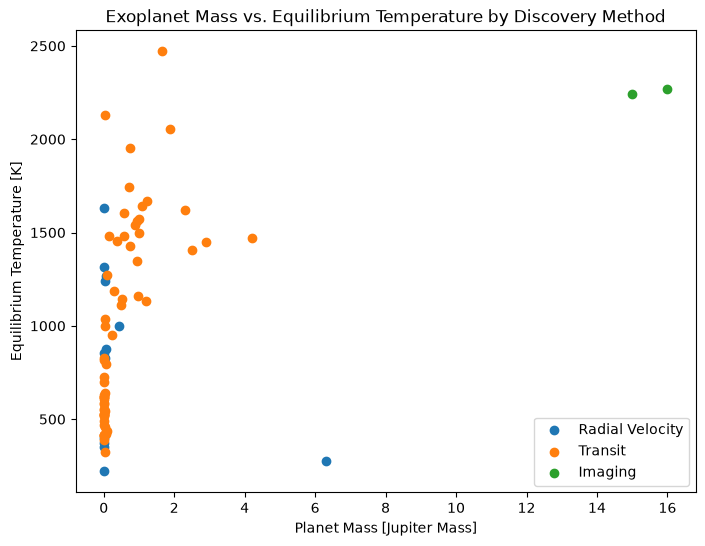

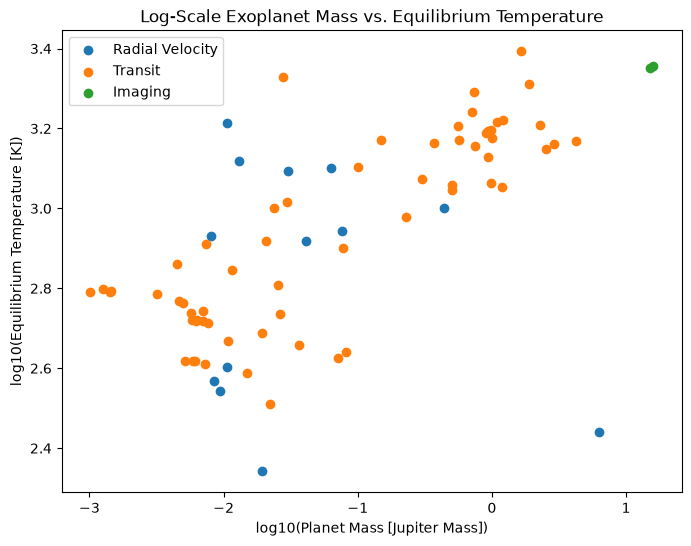


--- Coldest Planet (> 5 Jupiter Masses) ---
Index: 76
Name: eps Ind A b
Equilibrium Temp: 275.0 K
Mass: 6.31 Jupiter Masses
Host Star Spectral Type: K5 V


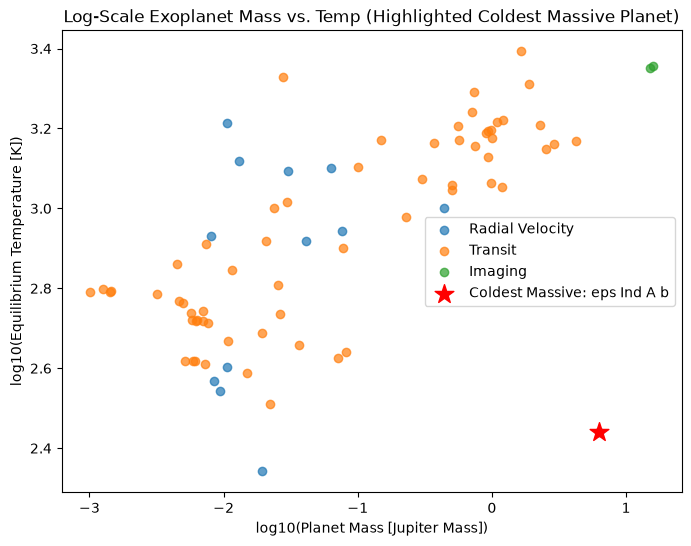

In [36]:
# 1. Analyze Discovery Method
method_counts = df_filtered['discoverymethod'].value_counts()
print("Discovery Methods and Counts:")
print(method_counts)
print(f"\nMost common method: {method_counts.idxmax()} ({method_counts.max()})")
print(f"Least common method: {method_counts.idxmin()} ({method_counts.min()})")

# 2. Scatter plot of Planet Mass vs Equilibrium Temperature
plt.figure(figsize=(8, 6))
methods = df_filtered['discoverymethod'].unique()

for method in methods:
    subset = df_filtered[df_filtered['discoverymethod'] == method]
    plt.scatter(subset['pl_bmassj'], subset['pl_eqt'], label=method)

plt.xlabel("Planet Mass [Jupiter Mass]")
plt.ylabel("Equilibrium Temperature [K]")
plt.title("Exoplanet Mass vs. Equilibrium Temperature by Discovery Method")
plt.legend()
plt.show()

# 3. Logarithmic Scale Scatter plot
plt.figure(figsize=(8, 6))

for method in methods:
    subset = df_filtered[df_filtered['discoverymethod'] == method]
    plt.scatter(np.log10(subset['pl_bmassj']), np.log10(subset['pl_eqt']), label=method)

plt.xlabel("log10(Planet Mass [Jupiter Mass])")
plt.ylabel("log10(Equilibrium Temperature [K])")
plt.title("Log-Scale Exoplanet Mass vs. Equilibrium Temperature")
plt.legend()
plt.show()

# 4. Filter for planets with mass > 5 Jupiter Masses and find the coldest planet
massive_planets = df_filtered[df_filtered['pl_bmassj'] > 5]
coldest_idx = massive_planets['pl_eqt'].idxmin()
coldest_planet = df_filtered.loc[coldest_idx]

# 5. Print details of the coldest massive planet
print("\n--- Coldest Planet (> 5 Jupiter Masses) ---")
print(f"Index: {coldest_idx}")
print(f"Name: {coldest_planet['pl_name']}")
print(f"Equilibrium Temp: {coldest_planet['pl_eqt']} K")
print(f"Mass: {coldest_planet['pl_bmassj']} Jupiter Masses")
print(f"Host Star Spectral Type: {coldest_planet['st_spectype']}")

#6. Re-plot logscale with the coldest planet highlighted
plt.figure(figsize=(8, 6))

for method in methods:
    subset = df_filtered[df_filtered['discoverymethod'] == method]
    plt.scatter(np.log10(subset['pl_bmassj']), np.log10(subset['pl_eqt']), label=method, alpha=0.7)

# Highlight coldest planet
plt.scatter(
    np.log10(coldest_planet['pl_bmassj']),
    np.log10(coldest_planet['pl_eqt']),
    color='red',
    marker='*',
    s=200,
    label=f"Coldest Massive: {coldest_planet['pl_name']}"
)

plt.xlabel("log10(Planet Mass [Jupiter Mass])")
plt.ylabel("log10(Equilibrium Temperature [K])")
plt.title("Log-Scale Exoplanet Mass vs. Temp (Highlighted Coldest Massive Planet)")
plt.legend()
plt.show()

In [ ]:
# 4.5

#1. "A temperate super-Jupiter imaged with JWST"

#2. Astronomers used the James Webb Space Telescope (JWST) Mid-Infrared Instrument (MIRI) to directly image a cold gas giant exoplanet orbiting the nearby 
#star Epsilon Indi A. The study confirmed a planet roughly 6 times more massive than Jupiter with a cool temperature around 275 K (about 2 °C / 35 °F), 
#making it a true solar system analog and a key benchmark for understanding gas giant cooling and atmosphere dynamics.

#3. Yes, The planet identified in the NASA Exoplanet Archive dataset filtered by mass (> 5 Jupiter masses) and lowest equilibrium temperature corresponds

#4. Epsilon Indi Ab is one of the coldest and closest exoplanets ever directly imaged by astronomers. Most directly imaged exoplanets are very young and glowing 
#hot, whereas Epsilon Indi Ab is much older, colder, and acts as a rare solar system analog close to our own cosmic neighborhood (~12 light-years away)

#5. Mass: The archive data lists the planet around $3.25 \text{ to } 6.5\ M_J$, which matches the paper's updated measurement of approximately $6.0 
#7.5 jupiter masses.
#Temperature: The dataset lists an equilibrium temperature around 275 K, which directly matches the paper's reported temperature of 275 K